# Credit Risk Dataset — Data Preprocessing & EDA

This notebook performs end-to-end data cleaning on `credit_risk_dataset.csv`.

**Pipeline:**
1. Load & inspect raw data
2. Handle missing values
3. Remove duplicate rows
4. Treat outliers
5. Feature engineering & encoding
6. Exploratory Data Analysis (EDA)
7. Save cleaned dataset

---
## 1 · Imports & Configuration

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 120

print('Libraries loaded')

Libraries loaded


---
## 2 · Load Raw Data

In [40]:
RAW_PATH = '../data/raw/credit_risk_dataset.csv'
CLEAN_PATH = '../data/processed/credit_risk_cleaned.csv'

df_raw = pd.read_csv(RAW_PATH)
print(f'Raw dataset shape: {df_raw.shape}')
df_raw.head()

Raw dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


---
## 3 · Initial Inspection

In [41]:
df_raw.info()
print("-"*100)
df_raw.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
-------------------------------

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [42]:
df_raw.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [43]:
# Unique values per categorical column
for col in df_raw.select_dtypes(include='object').columns:
    print(f'{col}: {df_raw[col].unique().tolist()}')

person_home_ownership: ['RENT', 'OWN', 'MORTGAGE', 'OTHER']
loan_intent: ['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
loan_grade: ['D', 'B', 'C', 'A', 'E', 'F', 'G']
cb_person_default_on_file: ['Y', 'N']


In [44]:
# Target distribution
print('loan_status value counts:')
print(df_raw['loan_status'].value_counts())
print(df_raw["loan_status"].value_counts(normalize=True)*100)
print(f"\nDefault rate: {df_raw['loan_status'].mean():.2%}")

loan_status value counts:
loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

Default rate: 21.82%


---
## 4 · Missing Value Analysis & Imputation

Two columns have missing values:
- `person_emp_length` — 895 nulls  
- `loan_int_rate` — 3,116 nulls

In [45]:
# Work on a copy from here
df = df_raw.copy()

# Missing value summary
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2) 
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)
print(missing_df)

                   Missing Count  Missing %
loan_int_rate               3116       9.56
person_emp_length            895       2.75


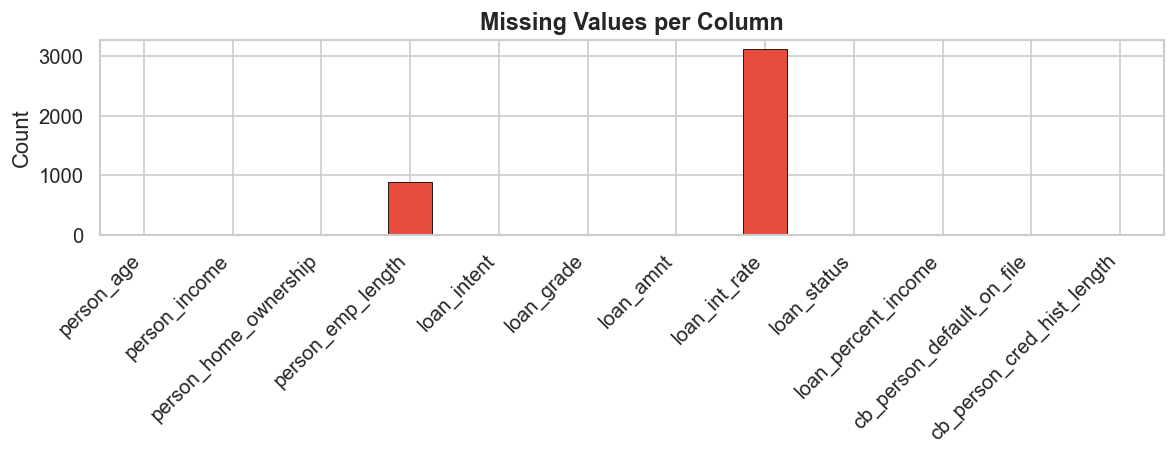

In [46]:
# Visualise missing values
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in df.isnull().sum()]
df.isnull().sum().plot.bar(ax=ax, color=colors, edgecolor='black', linewidth=0.5)
ax.set_title('Missing Values per Column', fontsize=14, fontweight='bold')
ax.set_ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [47]:
# Impute person_emp_length with median (skewed distribution)
median_emp = df['person_emp_length'].median()
df['person_emp_length'].fillna(median_emp, inplace=True)
print(f'person_emp_length imputed with median = {median_emp}')

# Impute loan_int_rate with median grouped by loan_grade (rate strongly depends on grade)
median_rate_by_grade = df.groupby('loan_grade')['loan_int_rate'].transform('median')
df['loan_int_rate'] = df['loan_int_rate'].fillna(median_rate_by_grade)
print('loan_int_rate imputed with median per loan_grade')

# Verify no missing values remain

print(f'{df.isnull().sum()}\n All missing values handled — 0 remaining')

person_emp_length imputed with median = 4.0
loan_int_rate imputed with median per loan_grade
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64
 All missing values handled — 0 remaining


---
## 5 · Duplicate Removal

In [48]:
n_dupes = df.duplicated().sum()
print(f'Duplicate rows found: {n_dupes}')

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Shape after removing duplicates: {df.shape}')
print(f'{n_dupes} duplicate rows removed')

Duplicate rows found: 165
Shape after removing duplicates: (32416, 12)
165 duplicate rows removed


---
## 6 · Outlier Detection & Treatment

Key outliers identified:
- `person_age` — max 144 (impossible ages > 100)
- `person_emp_length` — max 123 (unrealistic employment length > 60 years)
- `person_income` — a few extreme values > $1M

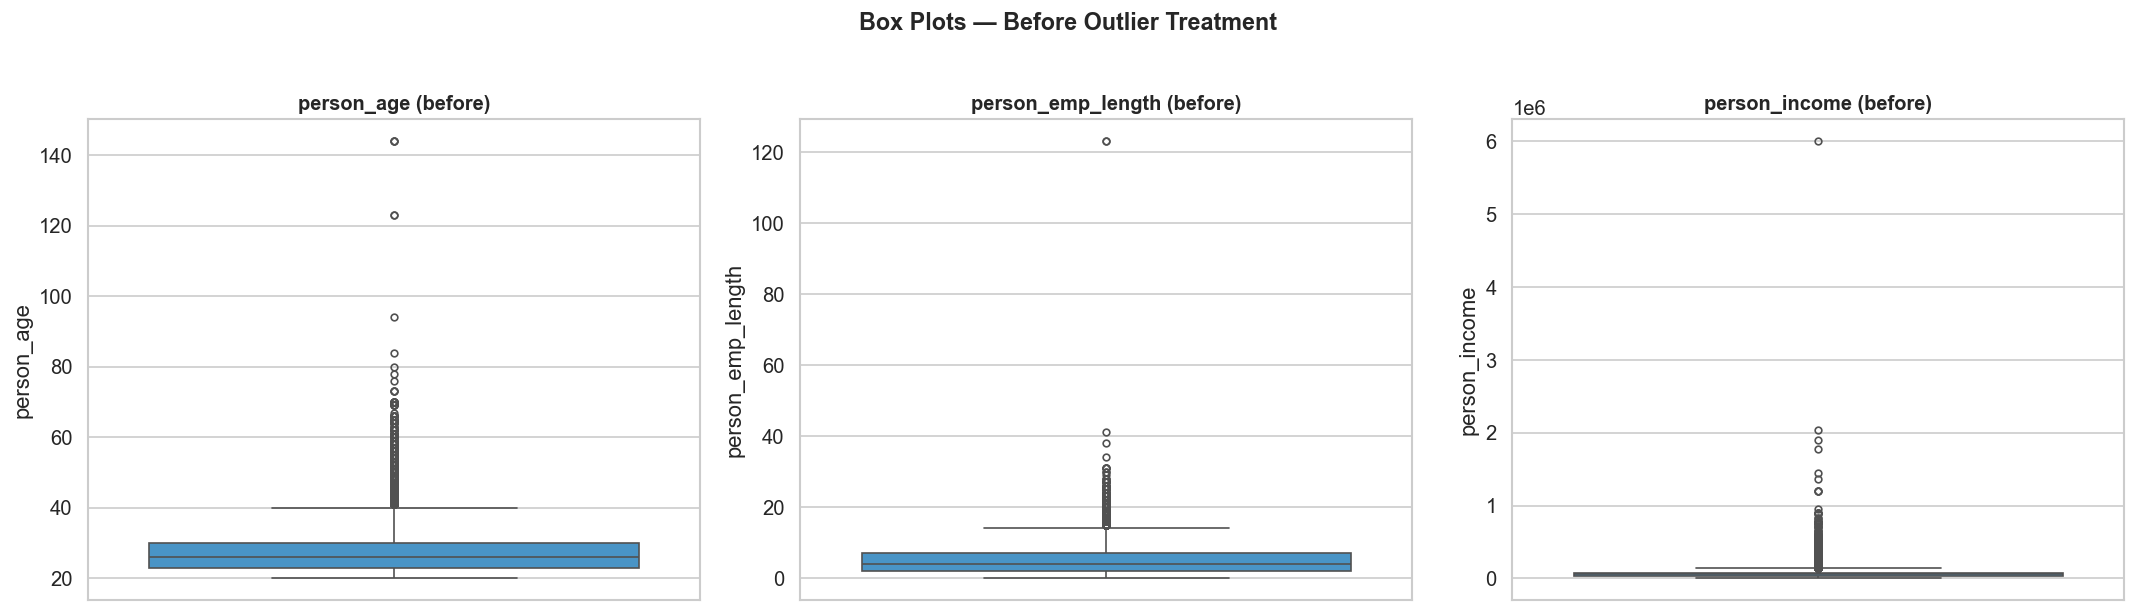

In [49]:
# Visualise distributions before outlier treatment
outlier_cols = ['person_age', 'person_emp_length', 'person_income']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], ax=ax, color='#3498db', flierprops={'marker': 'o', 'markersize': 4})
    ax.set_title(f'{col} (before)', fontsize=12, fontweight='bold')
fig.suptitle('Box Plots — Before Outlier Treatment', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [50]:
before = len(df)

# Remove physically impossible ages (> 100)
df = df[df['person_age'] <= 100]
print(f'Removed {before - len(df)} rows with person_age > 100')

# Remove unrealistic employment lengths (> 60 years)
before2 = len(df)

df = df[df['person_emp_length'] <= 60]
print(f'Removed {before2 - len(df)} rows with person_emp_length > 60')

# Cap person_income at 99.5th percentile
income_cap = df['person_income'].quantile(0.995)
n_capped = (df['person_income'] > income_cap).sum()
df['person_income'] = df['person_income'].clip(upper=income_cap)
print(f'Capped {n_capped} income values at {income_cap:,.0f}')

df.reset_index(drop=True, inplace=True)
print(f'\n Shape after outlier treatment: {df.shape}')

Removed 5 rows with person_age > 100
Removed 2 rows with person_emp_length > 60
Capped 136 income values at 300,000

 Shape after outlier treatment: (32409, 12)


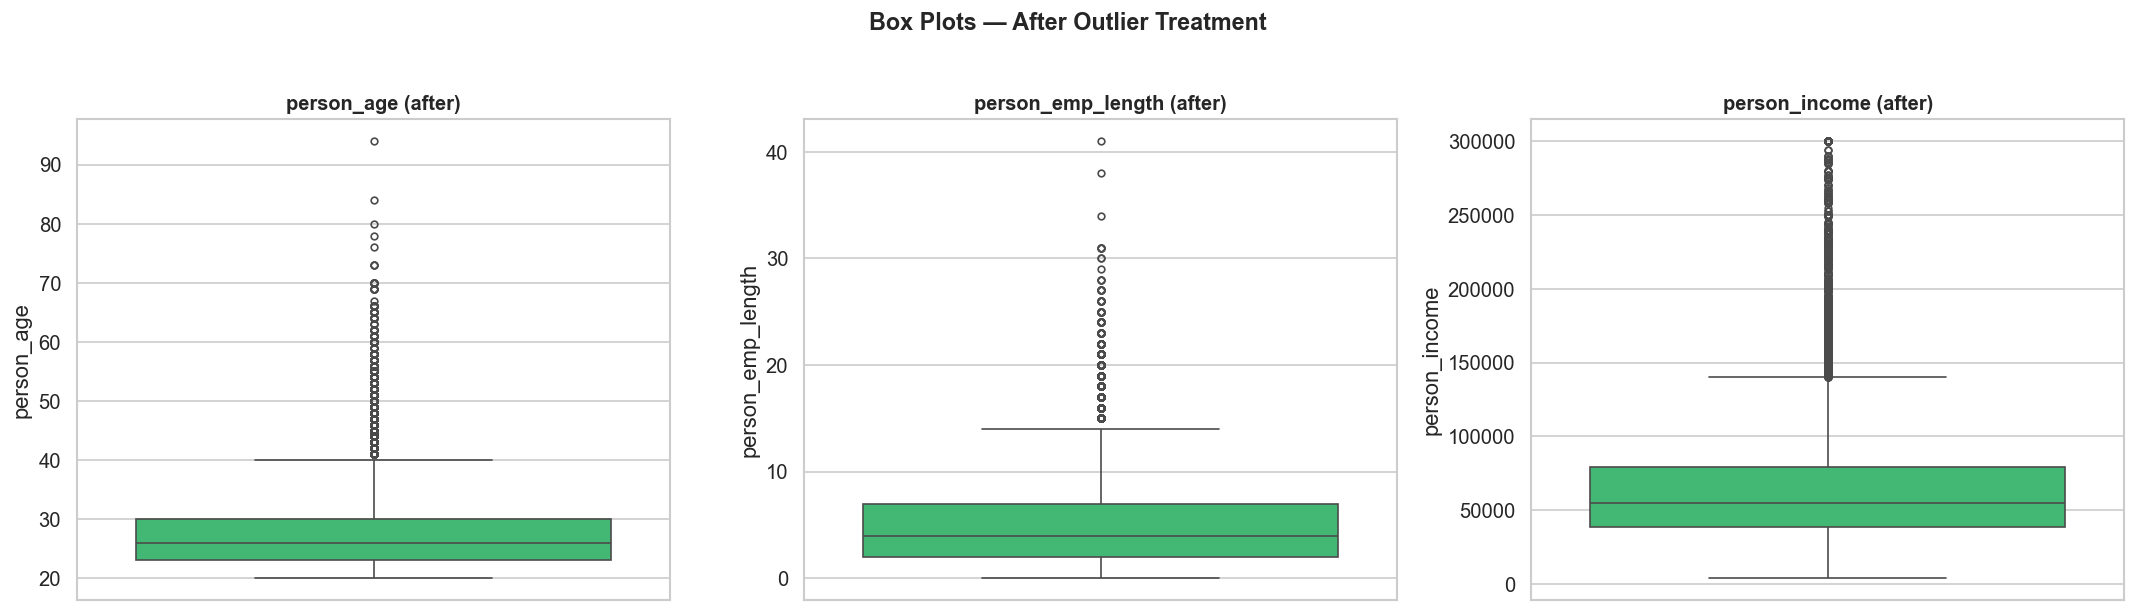

In [51]:
# Visualise distributions after outlier treatment
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], ax=ax, color='#2ecc71', flierprops={'marker': 'o', 'markersize': 4})
    ax.set_title(f'{col} (after)', fontsize=12, fontweight='bold')
fig.suptitle('Box Plots — After Outlier Treatment', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 7 · Exploratory Data Analysis (EDA)

### 7.1 · Target Variable Distribution

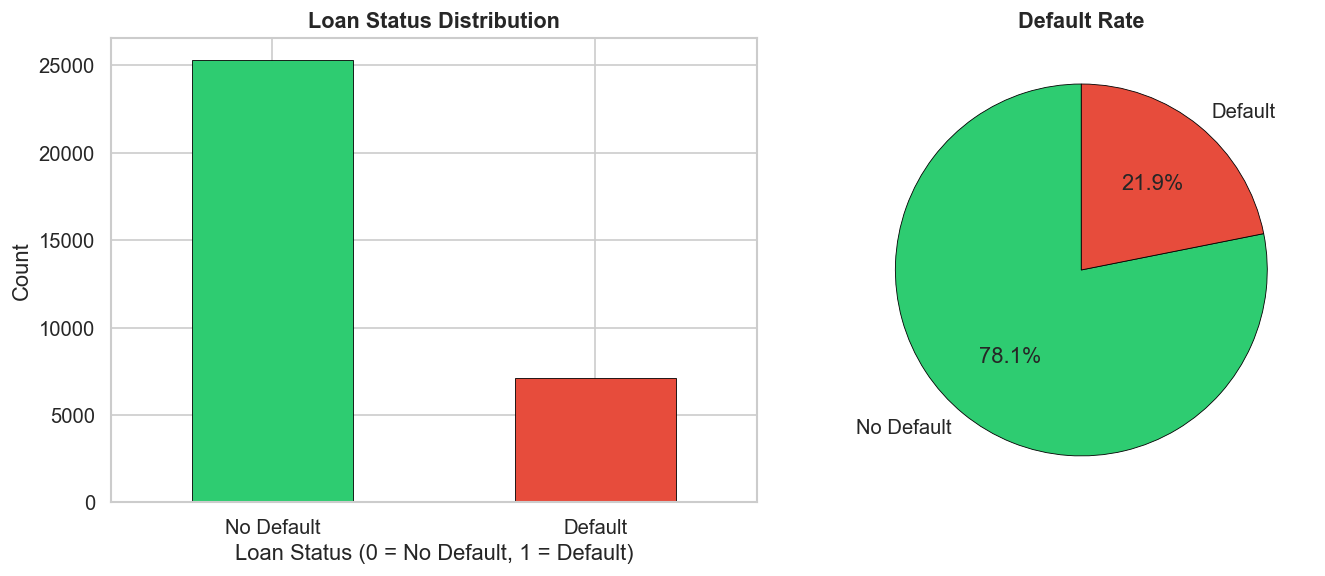

Default rate: 21.87%


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
colors_target = ['#2ecc71', '#e74c3c']
df['loan_status'].value_counts().plot.bar(ax=axes[0], color=colors_target, edgecolor='black', linewidth=0.5)
axes[0].set_title('Loan Status Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Loan Status (0 = No Default, 1 = Default)')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['No Default', 'Default'], rotation=0)

# Pie chart
df['loan_status'].value_counts().plot.pie(
    ax=axes[1], autopct='%1.1f%%', colors=colors_target,
    labels=['No Default', 'Default'], startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.5}
)
axes[1].set_title('Default Rate', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()
print(f"Default rate: {df['loan_status'].mean():.2%}")

### 7.2 · Numerical Feature Distributions

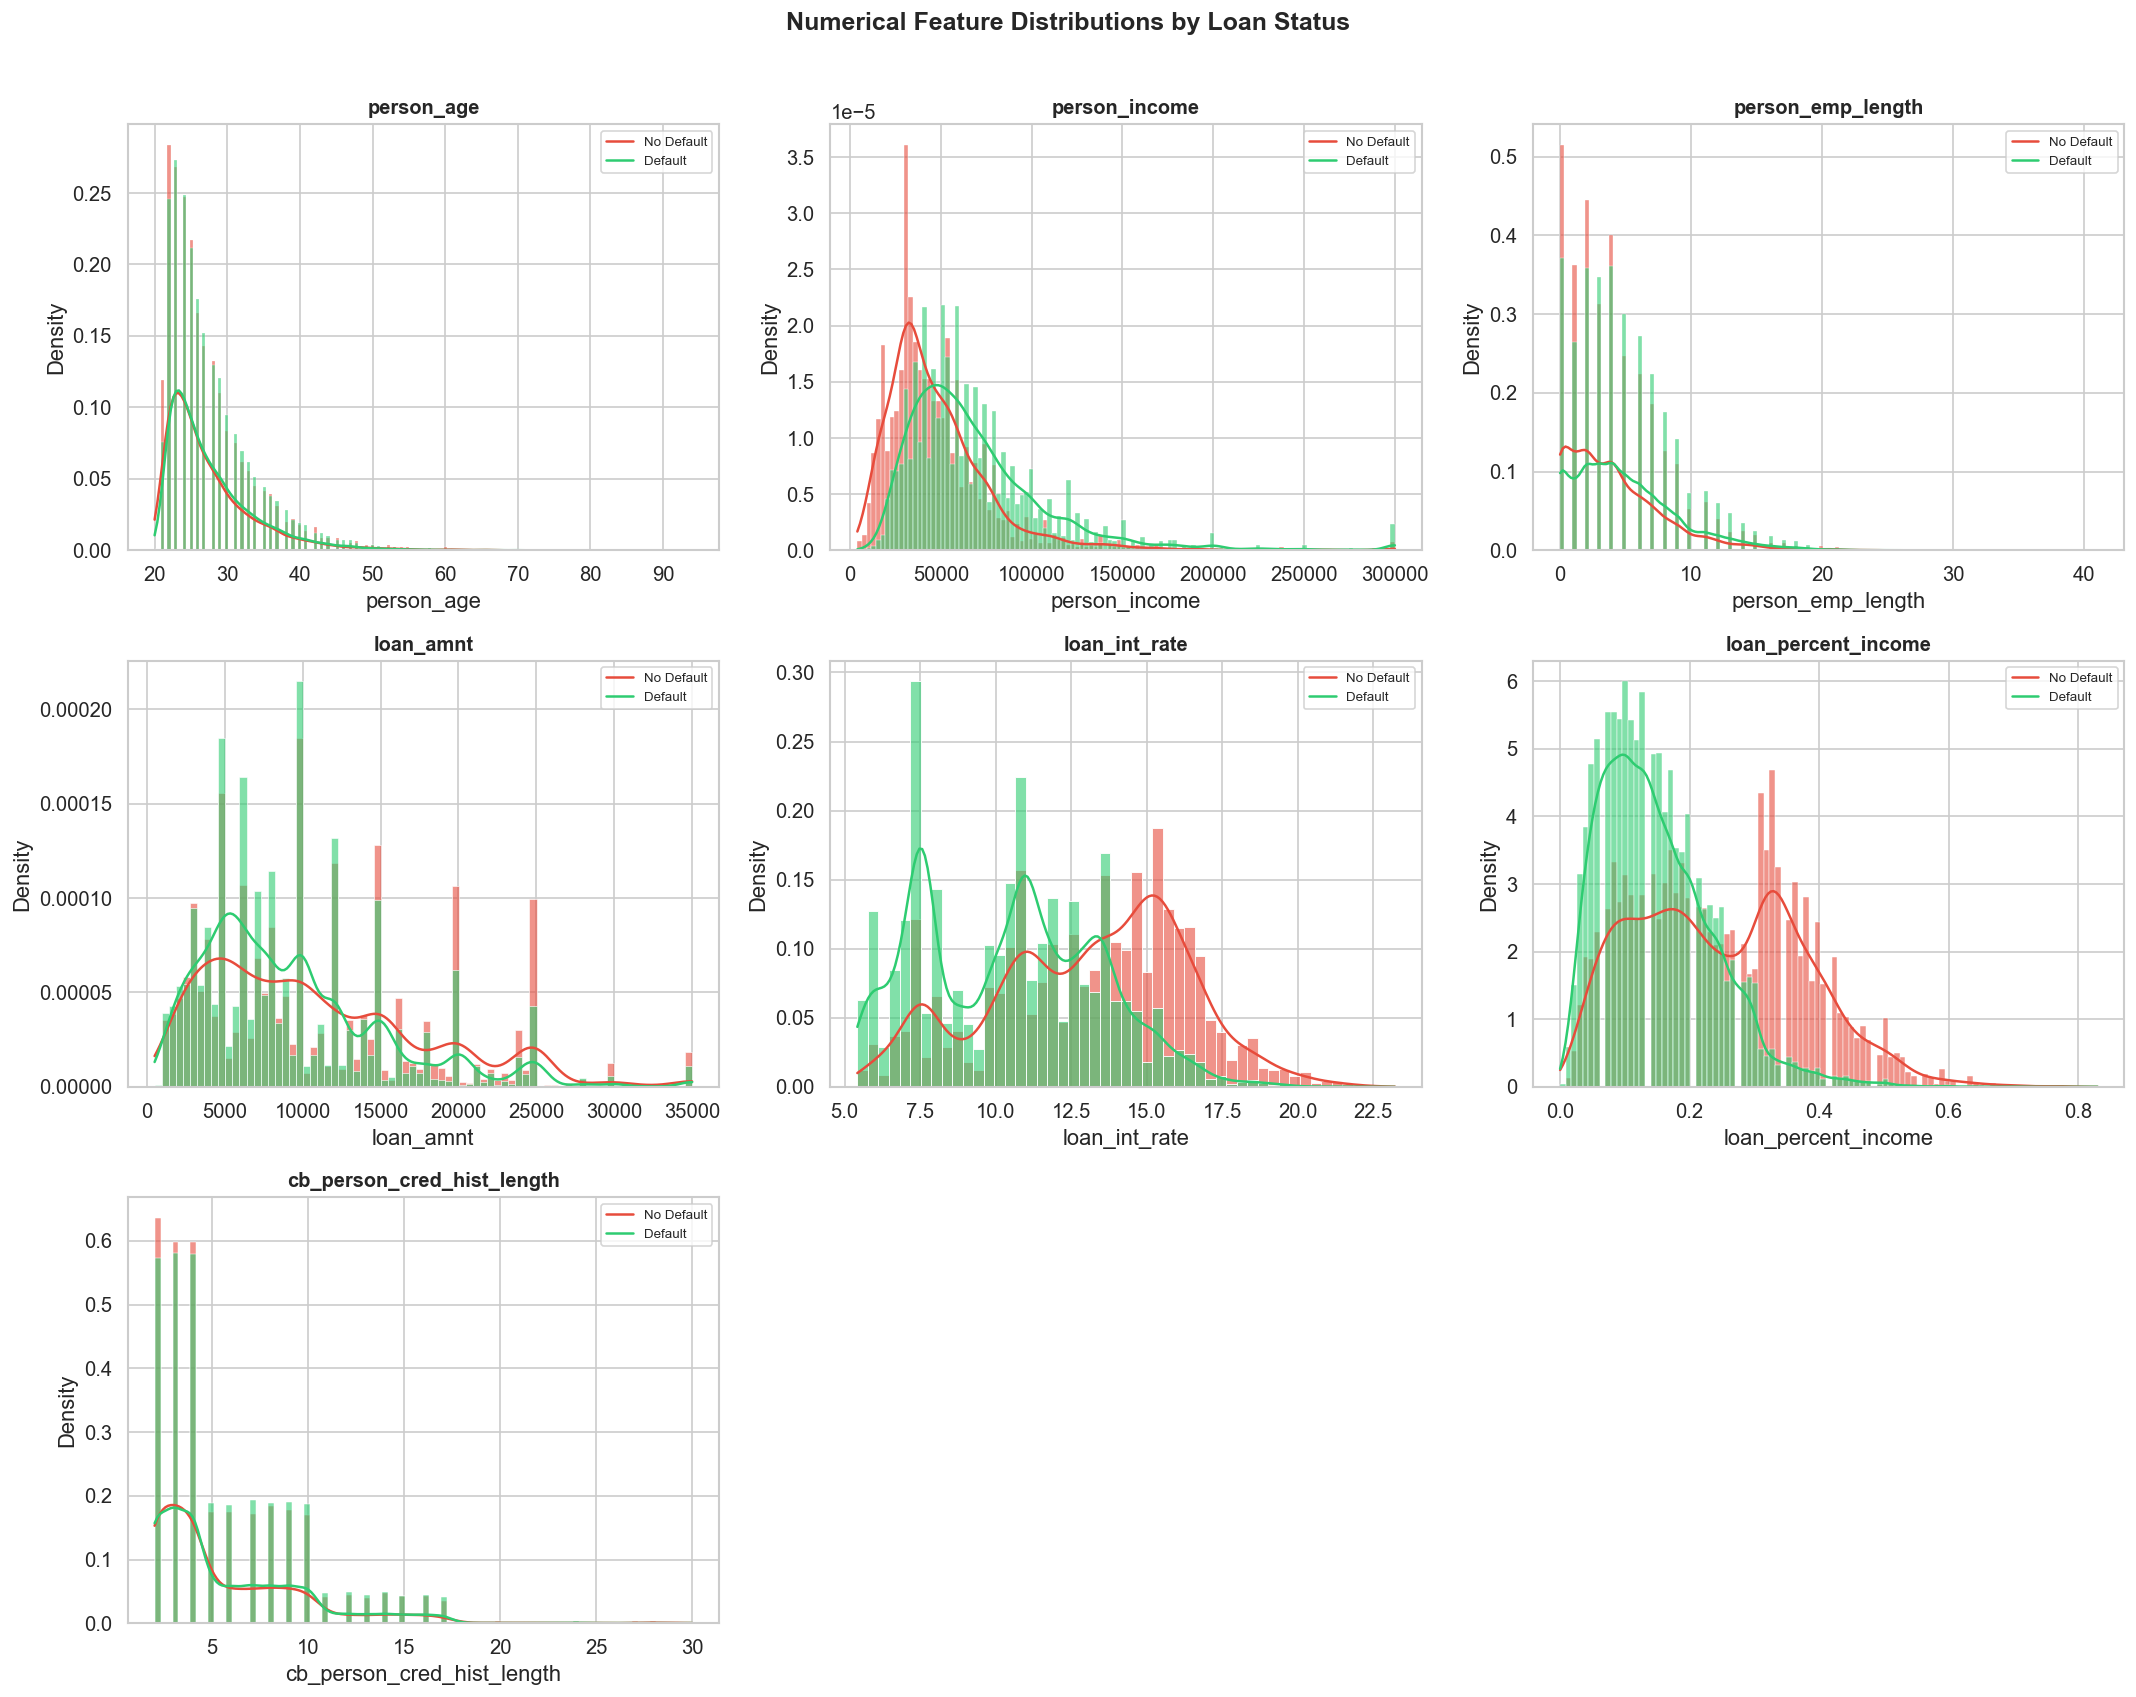

In [53]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols.remove('loan_status')  # exclude target

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    if i < len(axes):
        sns.histplot(data=df, x=col, hue='loan_status', kde=True, ax=axes[i],
                     palette=colors_target, alpha=0.6, stat='density', common_norm=False)
        axes[i].set_title(col, fontsize=12, fontweight='bold')
        axes[i].legend(['No Default', 'Default'], fontsize=8)

# Hide unused subplots
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Numerical Feature Distributions by Loan Status', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 7.3 · Categorical Feature Distributions

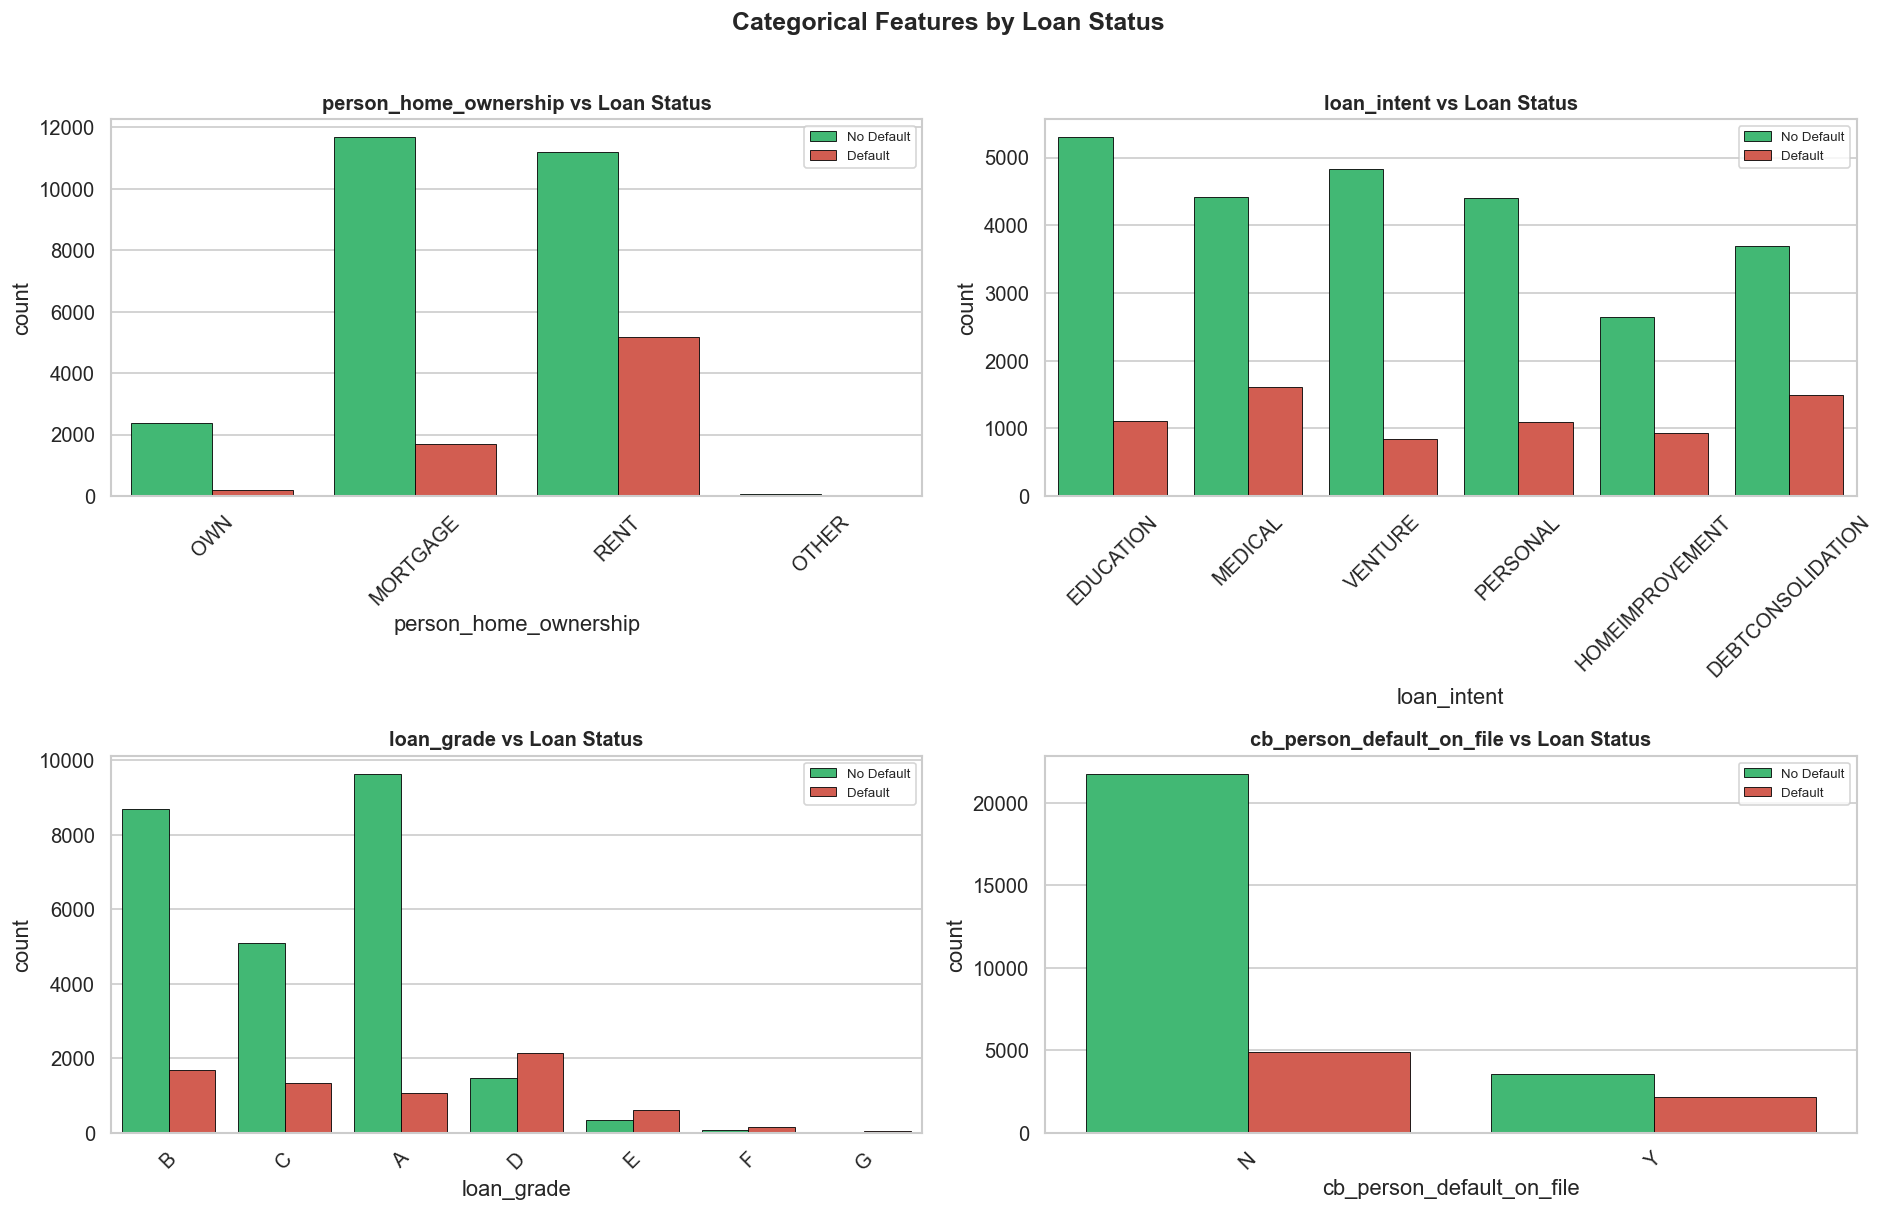

In [54]:
cat_cols = df.select_dtypes(include='object').columns.tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='loan_status', ax=axes[i],
                  palette=colors_target, edgecolor='black', linewidth=0.5)
    axes[i].set_title(f'{col} vs Loan Status', fontsize=12, fontweight='bold')
    axes[i].legend(['No Default', 'Default'], fontsize=8)
    axes[i].tick_params(axis='x', rotation=45)

fig.suptitle('Categorical Features by Loan Status', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 7.4 · Default Rate by Loan Grade

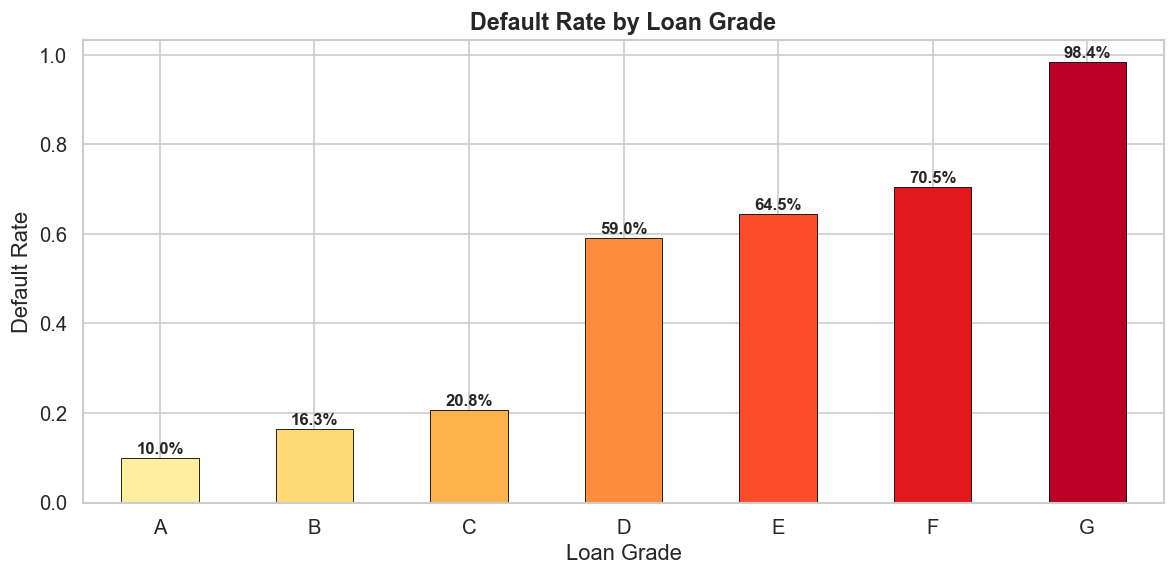

In [55]:
grade_default = df.groupby('loan_grade')['loan_status'].mean().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
grade_colors = sns.color_palette('YlOrRd', len(grade_default))
grade_default.plot.bar(ax=ax, color=grade_colors, edgecolor='black', linewidth=0.5)
ax.set_title('Default Rate by Loan Grade', fontsize=14, fontweight='bold')
ax.set_ylabel('Default Rate')
ax.set_xlabel('Loan Grade')
ax.set_xticklabels(grade_default.index, rotation=0)

for idx, val in enumerate(grade_default):
    ax.text(idx, val + 0.01, f'{val:.1%}', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### 7.5 · Correlation Heatmap

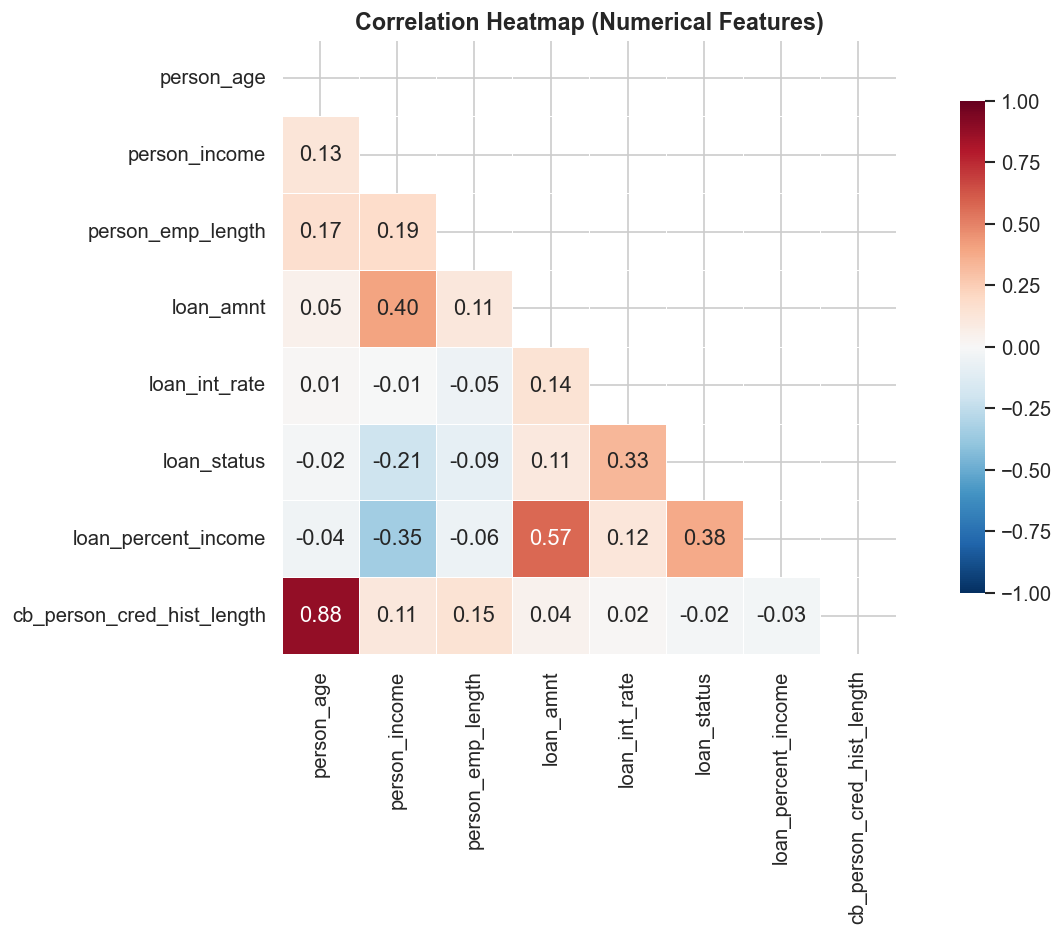

In [56]:
fig, ax = plt.subplots(figsize=(12, 8))
corr_matrix = df.select_dtypes(include=np.number).corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            square=True, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap (Numerical Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8 · Feature Engineering & Encoding

In [57]:
# --- Ordinal encoding for loan_grade (A=1 best → G=7 worst) ---
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
df['loan_grade_enc'] = df['loan_grade'].map(grade_map)
print('loan_grade encoded (ordinal):', grade_map)

# --- Binary encoding for cb_person_default_on_file ---
df['cb_default_enc'] = df['cb_person_default_on_file'].map({'Y': 1, 'N': 0})
print('cb_person_default_on_file encoded: Y=1, N=0')

# --- One-hot encoding for nominal categoricals ---
nominal_cols = ['person_home_ownership', 'loan_intent']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)
print(f'One-hot encoded: {nominal_cols}')

# Drop original encoded columns that are now redundant
df.drop(columns=['loan_grade', 'cb_person_default_on_file'], inplace=True)

print(f'\n Final shape: {df.shape}')
df.head()

loan_grade encoded (ordinal): {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
cb_person_default_on_file encoded: Y=1, N=0
One-hot encoded: ['person_home_ownership', 'loan_intent']

 Final shape: (32409, 18)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,loan_grade_enc,cb_default_enc,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,9600,5.0,1000,11.14,0,0.10,2,2,0,0,1,0,1,0,0,0,0
1,25,9600,1.0,5500,12.87,1,0.57,3,3,0,0,0,0,0,0,1,0,0
2,23,65500,4.0,35000,15.23,1,0.53,2,3,0,0,0,1,0,0,1,0,0
3,24,54400,8.0,35000,14.27,1,0.55,4,3,1,0,0,1,0,0,1,0,0
4,21,9900,2.0,2500,7.14,1,0.25,2,1,0,0,1,0,0,0,0,0,1


---
## 9 · Final Validation

In [58]:
print(df.isnull().sum())

person_age                     0
person_income                  0
person_emp_length              0
loan_amnt                      0
loan_int_rate                  0
loan_status                    0
loan_percent_income            0
cb_person_cred_hist_length     0
loan_grade_enc                 0
cb_default_enc                 0
person_home_ownership_OTHER    0
person_home_ownership_OWN      0
person_home_ownership_RENT     0
loan_intent_EDUCATION          0
loan_intent_HOMEIMPROVEMENT    0
loan_intent_MEDICAL            0
loan_intent_PERSONAL           0
loan_intent_VENTURE            0
dtype: int64


In [59]:
print('=' * 50)
print('FINAL DATASET SUMMARY')
print('=' * 50)
print(f'Rows          : {df.shape[0]:,}')
print(f'Columns       : {df.shape[1]}')
print(f'Missing values: {df.isnull().sum().sum()}')
print(f'Duplicates    : {df.duplicated().sum()}')
print(f'Target (0)    : {(df["loan_status"] == 0).sum():,}')
print(f'Target (1)    : {(df["loan_status"] == 1).sum():,}')
print(f'Default rate  : {df["loan_status"].mean():.2%}')
print('=' * 50)
print()
print('Column dtypes:')
print(df.dtypes)

FINAL DATASET SUMMARY
Rows          : 32,409
Columns       : 18
Missing values: 0
Duplicates    : 0
Target (0)    : 25,321
Target (1)    : 7,088
Default rate  : 21.87%

Column dtypes:
person_age                       int64
person_income                    int64
person_emp_length              float64
loan_amnt                        int64
loan_int_rate                  float64
loan_status                      int64
loan_percent_income            float64
cb_person_cred_hist_length       int64
loan_grade_enc                   int64
cb_default_enc                   int64
person_home_ownership_OTHER      int32
person_home_ownership_OWN        int32
person_home_ownership_RENT       int32
loan_intent_EDUCATION            int32
loan_intent_HOMEIMPROVEMENT      int32
loan_intent_MEDICAL              int32
loan_intent_PERSONAL             int32
loan_intent_VENTURE              int32
dtype: object


---
## 10 · Save Cleaned Dataset

In [60]:
import os
os.makedirs(os.path.dirname(CLEAN_PATH), exist_ok=True)

df.to_csv(CLEAN_PATH, index=False)
print(f'Cleaned dataset saved to: {CLEAN_PATH}')
print(f'   Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')

Cleaned dataset saved to: ../data/processed/credit_risk_cleaned.csv
   Rows: 32,409 | Columns: 18
